# Introduction to Dynamical Systems

This notebook records introductory computational exercises on **autonomous differential equations, fixed points, stability, and phase portraits**. It begins with one-dimensional nonlinear flows, introduces a physical relaxation model, and then moves to two-dimensional linear systems. The aim is to connect qualitative predictions obtained from the equations with numerical trajectories and visualisations.

### Approach

For an autonomous system $\dot{x}=f(x)$, a **fixed point** $x_*$ satisfies $f(x_*)=0$. In one dimension, the sign of $f(x)$ tells us the direction of motion; where $f'(x_*)<0$, a hyperbolic equilibrium is locally attracting, while $f'(x_*)>0$ indicates local repulsion. For a two-dimensional linear system $\dot{\mathbf{x}}=A\mathbf{x}$, the eigenvalues and eigenvectors of $A$ describe the nature of the equilibrium and the preferred directions of motion.

**What the code explores:** right-hand-side curves, phase lines and phase planes, numerical ODE solutions, potential functions, matrix exponentials, eigenvalue-based stability, and numerical-versus-analytical comparisons.

The examples are independent: some reuse names such as `f`, `x`, or `dx_dt`. Run the notebook **from top to bottom** in a Jupyter environment, or run an individual example after executing the initial imports. The original simulation cells and their saved plots have been retained.


## Part I — One-dimensional autonomous systems

In a one-dimensional autonomous equation, the state $x(t)$ changes according to $\dot{x}=f(x)$. A **phase line** marks equilibria where $f(x)=0$ and uses arrows to show whether trajectories move towards or away from them. Unlike a graph of $x(t)$, a phase line conveys the qualitative dynamics without choosing one initial condition.

The next examples compare stable and unstable fixed points, basins of attraction, and the effect of changing the shape of $f(x)$. Several also admit a **potential function** $V(x)$ satisfying $\dot{x}=-V'(x)$; trajectories then move downhill because $\frac{dV}{dt}=-[V'(x)]^2\leq0$.


In [1]:
# Importing the necessary libraries: 
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

### Model 1 — Cubic flow and two attracting equilibria

Consider the nonlinear, autonomous differential equation

$$
\frac{dx}{dt}=x-x^3=x(1-x^2).
$$

This is a simple example of **bistability**: the system can approach one of two distinct steady states depending on its starting point. Solving $x-x^3=0$ gives three fixed points: $x_*=-1,0,1$. Since $f'(x)=1-3x^2$, the points $x_*=\pm1$ are locally stable ($f'=-2$), while $x_*=0$ is unstable ($f'=1$). Initial conditions below zero approach $-1$, and those above zero approach $1$; a trajectory starting exactly at zero stays there.

A related potential is

$$
V(x)=-\frac{x^2}{2}+\frac{x^4}{4}, \qquad \dot{x}=-\frac{dV}{dx}.
$$

The two minima of this **double-well potential** correspond to the stable equilibria. The code plots $f(x)$, a phase line with arrows, numerical solutions from multiple initial conditions, a finite-time map from initial to final states, and the potential. The final-state plot approximates the basins of attraction at $t=10$; it is not an exact infinite-time limit.


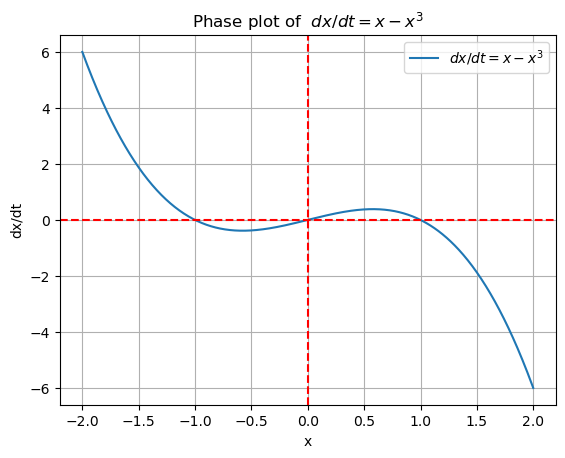

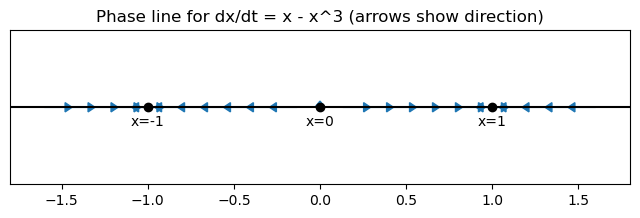

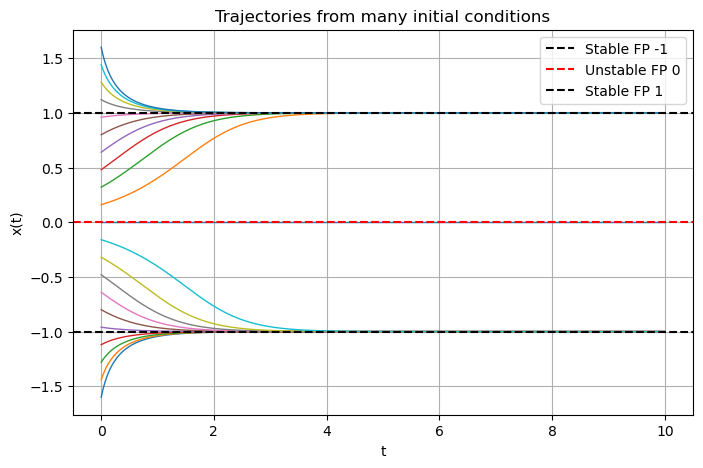

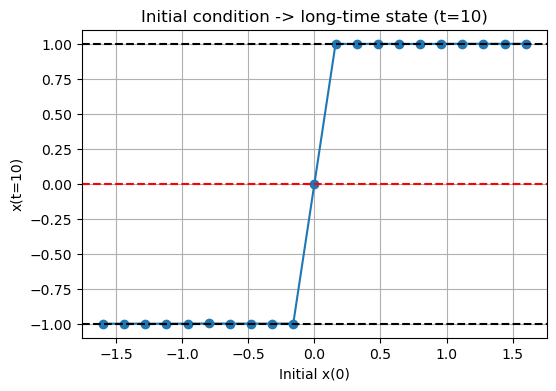

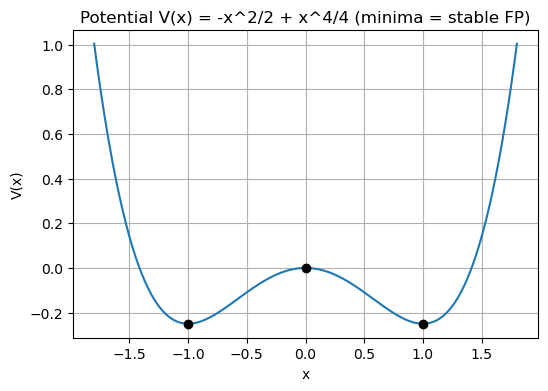

In [2]:
def dx_dt(x):
    return x-np.pow(x,3)

x=np.linspace(-2,2,1000)
dx=dx_dt(x)

plt.plot(x,dx,label='$dx/dt = x-x^3$')
plt.axhline(0,color='red',linestyle='--')
plt.axvline(0,color='red',linestyle='--')
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.title('Phase plot of  $dx/dt = x - x^3$')
plt.legend()
plt.grid(True)
plt.show()


# ODE
def f(t, x):
    return x - x**3

# time for integration
t_span = (0, 10)
t_eval = np.linspace(t_span[0], t_span[1], 400)

# 1) Phase line (direction arrows) -----------------------------------------
xs = np.linspace(-1.8, 1.8, 400)
fx = xs - xs**3

plt.figure(figsize=(8,2))
# draw horizontal axis
plt.hlines(0, xs.min(), xs.max(), colors='k')
# draw arrows: normalized direction
for xi, fi in zip(np.linspace(-1.6, 1.6, 25), (np.linspace(-1.6, 1.6, 25) - np.linspace(-1.6,1.6,25)**3)):
    dx = np.sign(fi) * 0.12  # arrow length small
    plt.arrow(xi, 0, dx, 0, head_width=0.06, head_length=0.04, fc='C0', ec='C0')
# mark fixed points
plt.plot([-1,0,1], [0,0,0], 'ko')
plt.text(-1, -0.12, "x=-1", ha='center')
plt.text(0, -0.12, "x=0", ha='center')
plt.text(1, -0.12, "x=1", ha='center')
plt.gca().get_yaxis().set_visible(False)
plt.title("Phase line for dx/dt = x - x^3 (arrows show direction)")
plt.xlim(xs.min(), xs.max())
plt.ylim(-0.5, 0.5)
plt.show()


# 2) Many trajectories and final attractor mapping -------------------------
initial_conditions = np.linspace(-1.6, 1.6, 21)
plt.figure(figsize=(8,5))
for x0 in initial_conditions:
    sol = solve_ivp(f, t_span, [x0], t_eval=t_eval, rtol=1e-8, atol=1e-10)
    plt.plot(sol.t, sol.y[0], lw=1)
# mark equilibria
plt.axhline(-1, color='k', linestyle='--', label='Stable FP -1')
plt.axhline(0, color='r', linestyle='--', label='Unstable FP 0')
plt.axhline(1, color='k', linestyle='--', label='Stable FP 1')
plt.xlabel('t'); plt.ylabel('x(t)')
plt.title('Trajectories from many initial conditions')
plt.grid(True); plt.legend()
plt.show()

# Basin mapping (where each IC ends up at final time)
finals = []
for x0 in initial_conditions:
    sol = solve_ivp(f, t_span, [x0], t_eval=[t_span[1]])
    finals.append(sol.y[0,-1])
plt.figure(figsize=(6,4))
plt.plot(initial_conditions, finals, 'o-')
plt.axhline(-1, color='k', linestyle='--')
plt.axhline(0, color='r', linestyle='--')
plt.axhline(1, color='k', linestyle='--')
plt.xlabel('Initial x(0)'); plt.ylabel('x(t=10)')
plt.title('Initial condition -> long-time state (t=10)')
plt.grid(True)
plt.show()


# 3) Potential function visualization ---------------------------------------
def V(x):
    return -0.5*x**2 + 0.25*x**4  # V' = -f

xx = np.linspace(-1.8, 1.8, 400)
plt.figure(figsize=(6,4))
plt.plot(xx, V(xx))
plt.plot([-1,0,1], [V(-1), V(0), V(1)], 'ko')
plt.title('Potential V(x) = -x^2/2 + x^4/4 (minima = stable FP)')
plt.xlabel('x'); plt.ylabel('V(x)')
plt.grid(True)
plt.show()


### Model 2 — Exponential growth and an unstable equilibrium

Next consider the linear scalar equation

$$
\frac{dx}{dt}=2x,\qquad x(0)=x_0.
$$

It has the exact solution $x(t)=x_0e^{2t}$ and only one fixed point, $x_*=0$. Because $f'(0)=2>0$, the equilibrium is **unstable**: positive initial states grow away from zero, while negative states become increasingly negative. The phase-line arrows therefore point away from the origin on both sides.

The equation is also a gradient flow with $V(x)=-x^2$, so $\dot{x}=-V'(x)$. Here the equilibrium sits at a maximum of the potential, consistent with instability. The code compares the right-hand-side graph, phase-line arrows, trajectories for several initial conditions, and this potential function. The plot limits may clip trajectories that grow rapidly; clipping is not convergence.


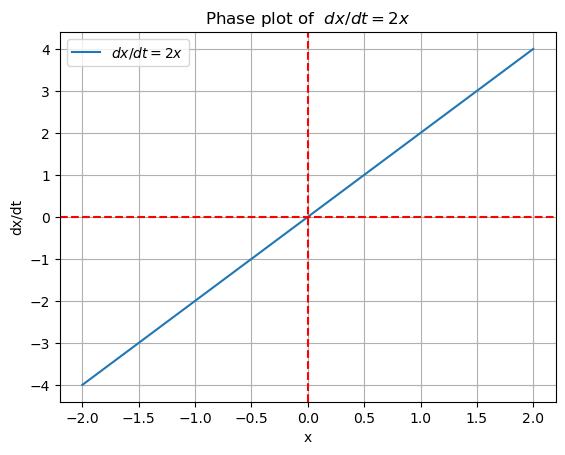

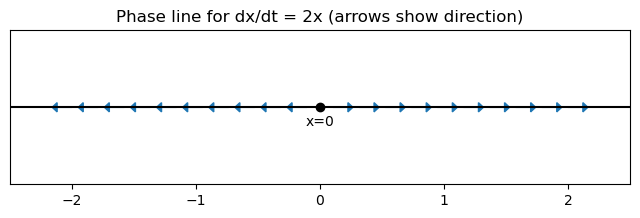

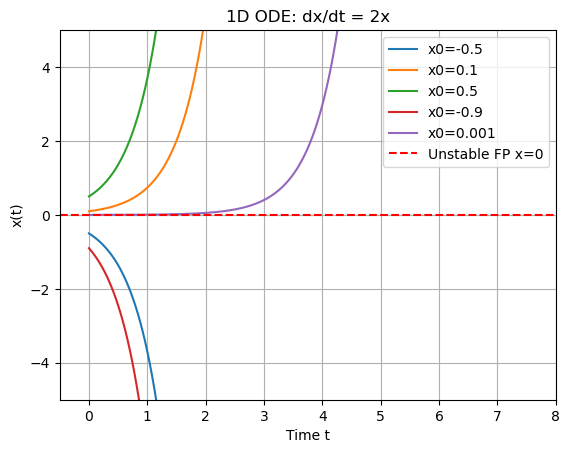

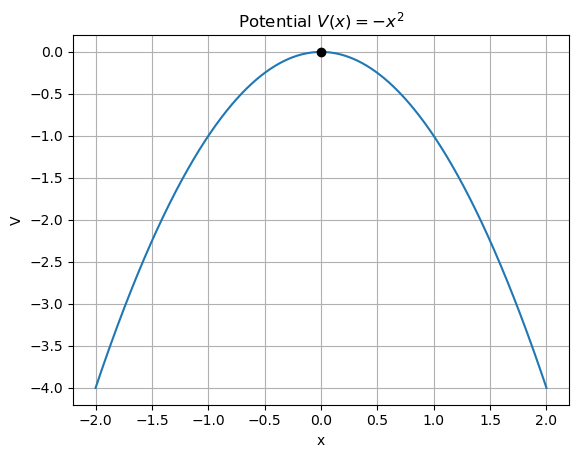

In [3]:
## We will first plot the RHS of the differential equation: 

## For the current model, dx/dt = 2x, the only fixed point is x = 0.

def dx_dt(x):
    return 2*x

x=np.linspace(-2,2,1000)
dx=dx_dt(x)

plt.plot(x,dx,label='$dx/dt = 2x$')
plt.axhline(0,color='red',linestyle='--')
plt.axvline(0,color='red',linestyle='--')
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.title('Phase plot of  $dx/dt = 2x$')
plt.legend()
plt.grid(True)
plt.show()


xs = np.linspace(-2.5, 2.5, 400)

plt.figure(figsize=(8,2))
plt.hlines(0, xs.min(), xs.max(), colors='k')

for xi in np.linspace(-2.0, 2.0, 20):
    fi = 2*xi
    dx_arrow = np.sign(fi) * 0.12  # small arrow length
    plt.arrow(xi, 0, dx_arrow, 0, head_width=0.06, head_length=0.04, fc='C0', ec='C0')

# mark fixed points
plt.plot([0], [0], 'ko')
plt.text(0, -0.12, "x=0", ha='center')

plt.gca().get_yaxis().set_visible(False)
plt.title("Phase line for dx/dt = 2x (arrows show direction)")
plt.xlim(xs.min(), xs.max())
plt.ylim(-0.5, 0.5)
plt.show()


def dx_dt(t,x):
    return 2*x

t_span = (0,10)
t_eval = np.linspace(t_span[0],t_span[1],500)

initial_conditions=[-0.5,0.1,0.5,-0.9,0.001]

for x0 in initial_conditions:
    sol=solve_ivp(dx_dt, t_span, [x0], t_eval=t_eval)
    plt.plot(sol.t,sol.y[0],label=f'x0={x0}')

plt.axhline(0, color='r', linestyle='--', label='Unstable FP x=0')

plt.xlabel("Time t")
plt.ylabel("x(t)")
plt.title("1D ODE: dx/dt = 2x")
plt.ylim(-5,5)
plt.xlim(-0.5,8)
plt.legend()
plt.grid()
plt.show()

def V(x):
    return -np.pow(x,2)

plt.plot(x,V(x))
plt.plot(0,0,'ko')
plt.title('Potential $V(x) = -x^2$')
plt.ylabel('V')
plt.xlabel('x')
plt.grid()
plt.show()

### Model 3 — A stable fixed point and an unstable threshold

For the autonomous equation

$$
\frac{dx}{dt}=x^2-1=(x-1)(x+1),
$$

the fixed points are $x_*=-1$ and $x_*=1$. The derivative $f'(x)=2x$ shows that $-1$ is **locally attracting** and $1$ is **repelling**. The vector field points right for $x<-1$, left for $-1<x<1$, and right for $x>1$. Consequently, initial conditions below $1$ move towards $-1$ (except an initial condition exactly at an equilibrium), whereas those above $1$ increase rather than approaching a stable equilibrium.

A potential satisfying $\dot{x}=-V'(x)$ is

$$
V(x)=x-\frac{x^3}{3}.
$$

The code visualises $f(x)$, the phase line, trajectories for different starting states, and the potential. **Numerical caution:** trajectories with $x(0)>1$ grow without bound in finite forward time, so an adaptive integrator may stop before the requested endpoint. The graph of $x(t)$ should therefore not be interpreted as a complete solution over the full time interval for every initial condition.


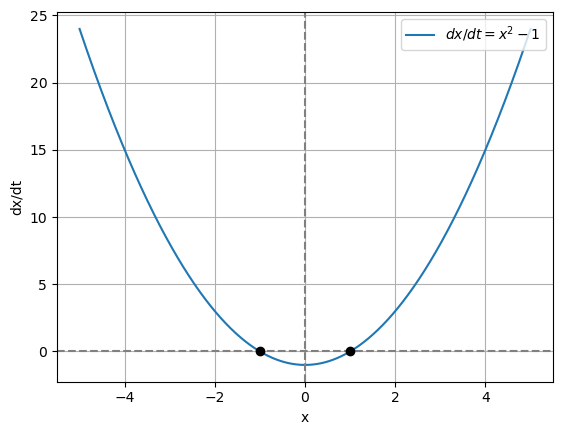

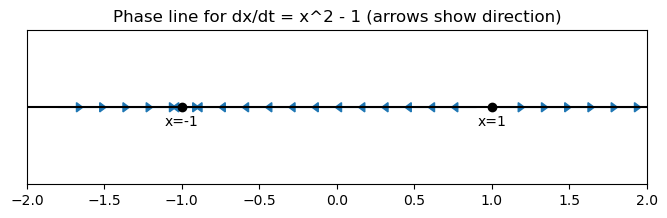

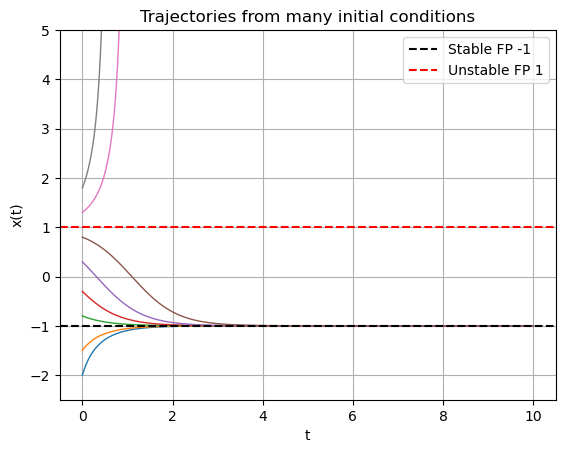

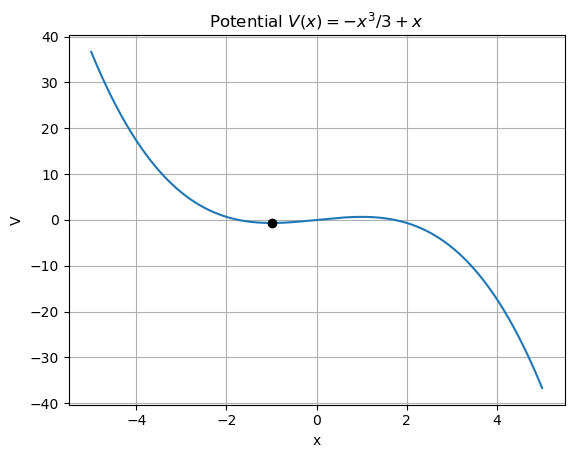

In [4]:
def dx_dt(x):
    return np.pow(x,2)-1

x=np.linspace(-5,5,1000)
dx=dx_dt(x)
plt.plot(x,dx,label='$dx/dt = x^2 - 1$')
plt.axhline(0,color='grey',linestyle='--')
plt.axvline(0,color='grey',linestyle='--')
plt.plot(1,0,'ko')
plt.plot(-1,0,'ko')
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.legend(loc='upper right')
plt.grid()
plt.show()



xs = np.linspace(-2, 2, 400)
fx = xs**2 - 1  # correct derivative

plt.figure(figsize=(8,2))
plt.hlines(0, xs.min(), xs.max(), colors='k')

for xi in np.linspace(-1.8, 1.8, 25):
    fi = xi**2 - 1
    dx_arrow = np.sign(fi) * 0.12  # small arrow length
    plt.arrow(xi, 0, dx_arrow, 0, head_width=0.06, head_length=0.04, fc='C0', ec='C0')

# mark fixed points
plt.plot([-1, 1], [0, 0], 'ko')
plt.text(-1, -0.12, "x=-1", ha='center')
plt.text(1, -0.12, "x=1", ha='center')

plt.gca().get_yaxis().set_visible(False)
plt.title("Phase line for dx/dt = x^2 - 1 (arrows show direction)")
plt.xlim(xs.min(), xs.max())
plt.ylim(-0.5, 0.5)
plt.show()

def f(t,x):
    return x**2 - 1

t_span=(0,10)
t_eval= np.linspace(t_span[0],t_span[1],500)
initial_conditions=[-2.0,-1.5,-0.8,-0.3,0.3,0.8,1.3,1.8]

for x0 in initial_conditions:
    sol = solve_ivp(f, t_span, [x0], t_eval=t_eval)
    plt.plot(sol.t, sol.y[0], lw=1)

plt.axhline(-1,color='black',linestyle='--',label='Stable FP -1')
plt.axhline(1,color='red',linestyle='--',label='Unstable FP 1')
plt.xlabel('t'); plt.ylabel('x(t)'); plt.title('Trajectories from many initial conditions')
plt.grid()
plt.legend()
plt.ylim(-2.5,5)
plt.show()

def V(x):
    return -np.pow(x,3)/3 + x

plt.plot(x,V(x))
plt.title('Potential $V(x) = -x^3/3 + x$')
plt.plot(-1,V(-1),'ko')
plt.ylabel('V')
plt.xlabel('x')
plt.grid()
plt.show()

### Model 4 — Logistic-type growth and saturation

The next nonlinear scalar equation is

$$
\frac{dx}{dt}=2x-x^2=x(2-x).
$$

It is a rescaled **logistic growth model**, with growth proportional to the state at small positive $x$ and a negative feedback term at larger values. Its equilibria are $x_*=0$ and $x_*=2$. The derivative $f'(x)=2-2x$ makes $0$ unstable and $2$ stable. For any positive initial state, the solution approaches the saturation level $x=2$ (from below or above).

The associated potential is

$$
V(x)=-x^2+\frac{x^3}{3}, \qquad \dot{x}=-V'(x).
$$

The code draws the right-hand-side curve, phase-line arrows, trajectories, and the potential. The chosen initial conditions deliberately include negative states to examine the mathematical vector field; negative populations have no physical interpretation in a population-growth model, and such solutions can diverge in finite forward time.


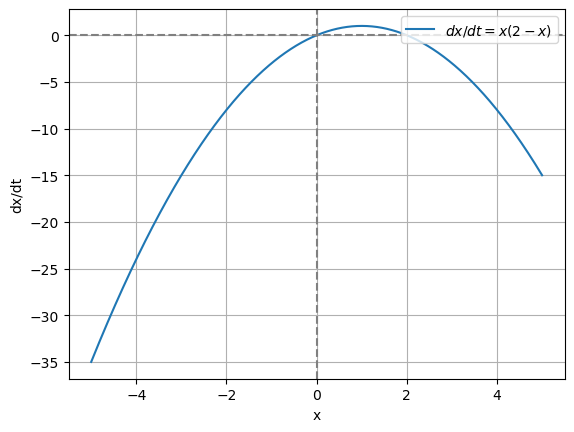

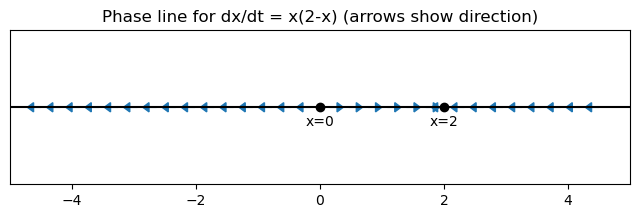

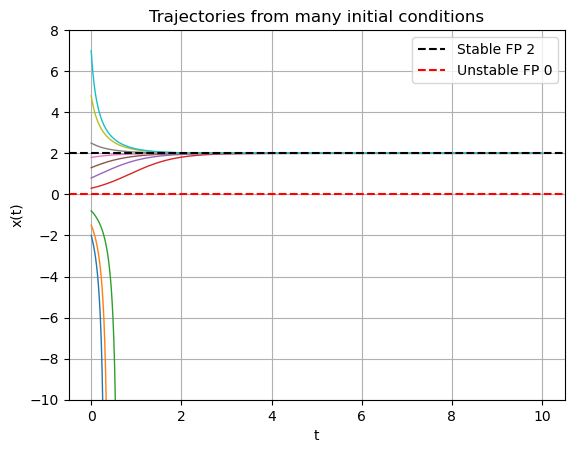

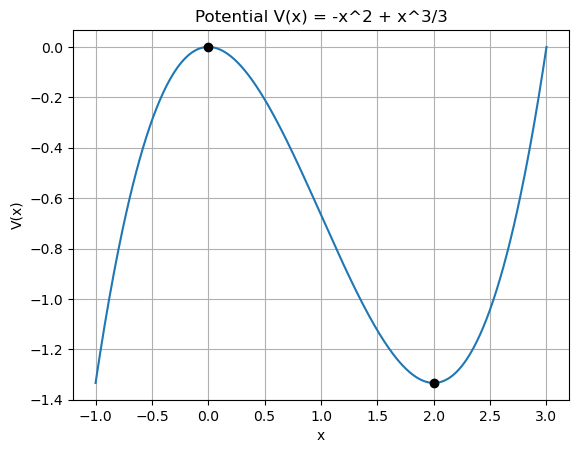

In [5]:
def dx_dt(x):
    return 2*x - x**2

x=np.linspace(-5,5,1000)
dx=dx_dt(x)
plt.plot(x,dx,label='$dx/dt = x(2-x)$')
plt.axhline(0,color='grey',linestyle='--')
plt.axvline(0,color='grey',linestyle='--')
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.legend(loc='upper right')
plt.grid()
plt.show()



xs = np.linspace(-5, 5, 1000)
fx = 2*xs - xs**2  # correct derivative

plt.figure(figsize=(8,2))
plt.hlines(0, xs.min(), xs.max(), colors='k')

for xi in np.linspace(-4.5, 4.5, 30):
    fi = 2*xi - xi**2
    dx_arrow = np.sign(fi) * 0.12  # small arrow length
    plt.arrow(xi, 0, dx_arrow, 0, head_width=0.06, head_length=0.1, fc='C0', ec='C0')

# mark fixed points
plt.plot([0, 2], [0, 0], 'ko')
plt.text(0, -0.12, "x=0", ha='center')
plt.text(2, -0.12, "x=2", ha='center')

plt.gca().get_yaxis().set_visible(False)
plt.title("Phase line for dx/dt = x(2-x) (arrows show direction)")
plt.xlim(xs.min(), xs.max())
plt.ylim(-0.5, 0.5)
plt.show()

def f(t,x):
    return 2*x - x**2

t_span=(0,10)
t_eval= np.linspace(t_span[0],t_span[1],500)
initial_conditions=[-2.0,-1.5,-0.8,0.3,0.8,1.3,1.8,2.5,4.8,7.0]

for x0 in initial_conditions:
    sol = solve_ivp(f, t_span, [x0], t_eval=t_eval)
    plt.plot(sol.t, sol.y[0], lw=1)

plt.axhline(2,color='black',linestyle='--',label='Stable FP 2')
plt.axhline(0,color='red',linestyle='--',label='Unstable FP 0')
plt.xlabel('t'); plt.ylabel('x(t)'); plt.title('Trajectories from many initial conditions')
plt.grid()
plt.legend()
plt.ylim(-10,8)
plt.show()




def V(x):
    return -x**2 + (x**3)/3  # potential function

xx = np.linspace(-1, 3, 400)
plt.plot(xx, V(xx))
plt.plot([0,2], [V(0), V(2)], 'ko')  # fixed points
plt.title("Potential V(x) = -x^2 + x^3/3")
plt.xlabel("x")
plt.ylabel("V(x)")
plt.grid(True)
plt.show()


## Part II — A physical first-order system: RC circuit

### Model 5 — Charging a capacitor through a resistor

A resistor $R$ and capacitor $C$ connected to a constant voltage source $V_0$ provide a physical example of a **stable first-order system**. Applying Kirchhoff's voltage law gives

$$
V_0-IR-\frac{Q}{C}=0,\qquad I=\frac{dQ}{dt},
$$

so the capacitor charge $Q(t)$ satisfies

$$
\frac{dQ}{dt}=\frac{V_0}{R}-\frac{Q}{RC}.
$$

The equilibrium charge is $Q_*=CV_0$. If $R,C>0$, the slope of the right-hand side is $-1/(RC)<0$, so the equilibrium is attracting. For $Q(0)=Q_0$, the exact solution is

$$
Q(t)=CV_0+(Q_0-CV_0)e^{-t/(RC)},
\qquad \tau=RC.
$$

The **time constant** $\tau$ sets the relaxation rate: after one $\tau$, the deviation from equilibrium is reduced by a factor of $e^{-1}$. In the code, $V_0=10$, $C=0.1$, and $R=10$, giving $Q_*=1$ and $\tau=1$ in the chosen units. The plots show the charge-flow phase line and numerical charging curves from multiple initial charges.


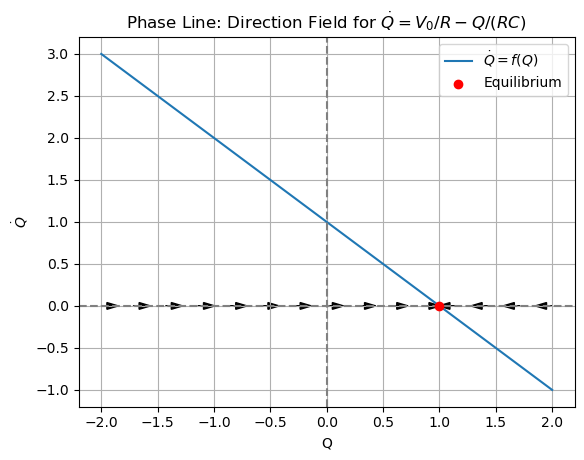

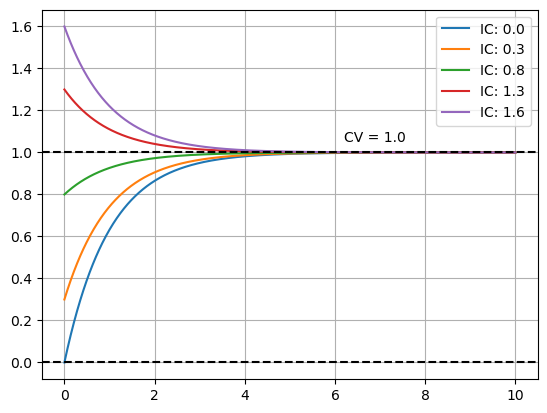

In [6]:
# An easy way to visualize this in a physical system is to take an RC circuit connected to a battery
# The equation governing the system is: V(battery) - IR - Vc = 0 (Kirchoff's Law)
# Where I is dQ/dt and Vc = Q/C
# =>  dQ/dt =  V0/R - Q/RC

# Analytically solving this diff eqn with initial value of Q0 gives:
"""
Q = V0*C + (Q0 - V0*C)*np.exp(-t/(R*C)) ; where R*C is tau : time constant
"""

def plot_dqdt(V0, C, R):
    Q = np.linspace(-2, 2, 1000)
    dqdt = V0 / R - Q / (R * C)
    
    # Plot the dq/dt vs Q line
    plt.plot(Q, dqdt, label=r'$\dot{Q} = f(Q)$')
    plt.axhline(0, color='grey', linestyle='--')
    plt.axvline(0, color='grey', linestyle='--')
    
    # Find equilibrium point: dq/dt = 0  => Q* = V0 * C
    Q_eq = V0 * C
    plt.scatter(Q_eq, 0, color='red', zorder=5, label='Equilibrium')
    
    # Add direction arrows along y=0
    # For points left and right of equilibrium
    for q in np.linspace(-2, 2, 15):
        f = V0 / R - q / (R * C)
        if f > 0:
            plt.arrow(q, 0, 0.05, 0, head_width=0.08, head_length=0.1, fc='black', ec='black')
        elif f < 0:
            plt.arrow(q, 0, -0.05, 0, head_width=0.08, head_length=0.1, fc='black', ec='black')
    
    plt.xlabel("Q")
    plt.ylabel(r"$\dot{Q}$")
    plt.title("Phase Line: Direction Field for $\dot{Q} = V_0/R - Q/(RC)$")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_dqdt(10,0.1,10)

def plot_qt(V0,C,R):

    def dqdt(t,Q):
        return  V0/R - Q/(R*C)
    t_span=(0,10)
    t_eval=np.linspace(t_span[0],t_span[1],1000)
    initial_conditions=[0.0,0.3,0.8,1.3,1.6]
    
    for x0 in initial_conditions:
        sol=solve_ivp(dqdt,t_span,[x0],t_eval=t_eval,rtol=1e-8,atol=1e-10)
        plt.plot(sol.t,sol.y[0],label=f'IC: {x0}')

    plt.grid()
    plt.legend()
    plt.axhline(1,color='black',linestyle='--')
    plt.axhline(0,color='black',linestyle='--')
    plt.annotate('CV = 1.0', xy=(6.2, 1.05))
    plt.show()

plot_qt(10,0.1,10)

## Part III — Linear systems and eigenvalue-based stability

### Model 6 — From a scalar linear equation to two-dimensional phase portraits

A general one-dimensional linear autonomous equation is

$$
\dot{x}=ax,\qquad x(t)=x_0e^{at}.
$$

Its equilibrium $x_*=0$ is stable for $a<0$ and unstable for $a>0$. The first plots illustrate this contrast with $a=-1$ (decay) and $a=0.5$ (growth).

The two-dimensional analogue is

$$
\dot{\mathbf{x}}=J\mathbf{x},\qquad
\mathbf{x}(t)=e^{Jt}\mathbf{x}_0,
$$

where the eigenvalues of $J$ control the local phase portrait. The script compares four matrices:

- **Pure rotation:** $J=\begin{pmatrix}0&-1\\1&0\end{pmatrix}$, eigenvalues $\pm i$, producing circular trajectories.
- **Stable spiral:** $J=\begin{pmatrix}-0.1&-1\\1&-0.1\end{pmatrix}$, eigenvalues $-0.1\pm i$, producing inward spirals.
- **Unstable spiral:** $J=\begin{pmatrix}0.1&-1\\1&0.1\end{pmatrix}$, eigenvalues $0.1\pm i$, producing outward spirals.
- **Saddle:** $J=\begin{pmatrix}1&0\\0&-1\end{pmatrix}$, eigenvalues $1$ and $-1$, with growth in one eigendirection and decay in the other.

The two-dimensional trajectories are integrated using SciPy's `solve_ivp`, and each trajectory is displayed in the phase plane. The examples distinguish **rotation**, **spiralling**, and **saddle behaviour** through the real and imaginary parts of eigenvalues. Purely imaginary eigenvalues here give neutral (not asymptotic) stability.


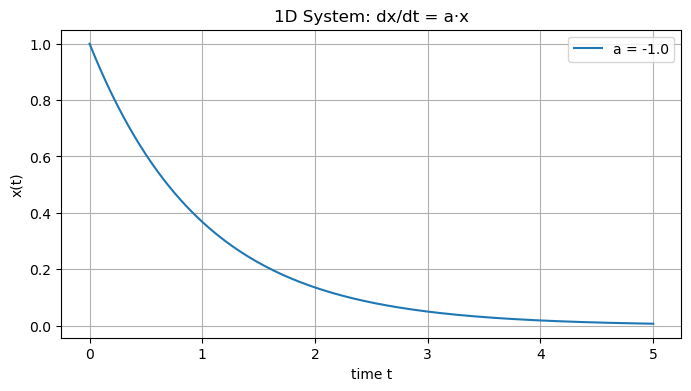

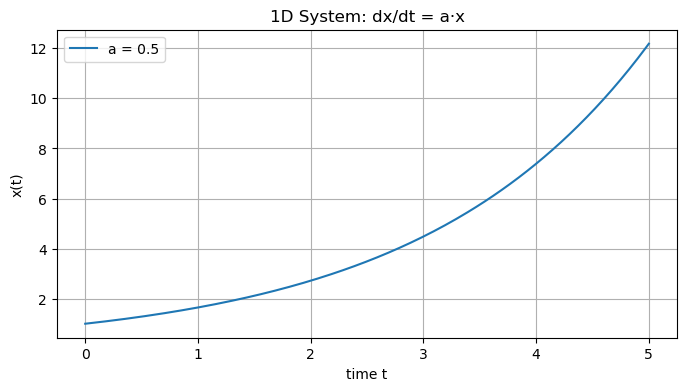

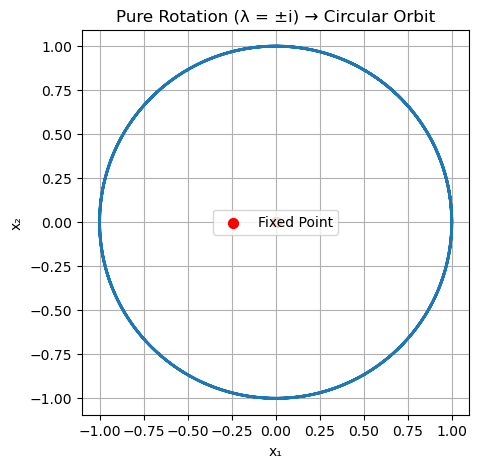

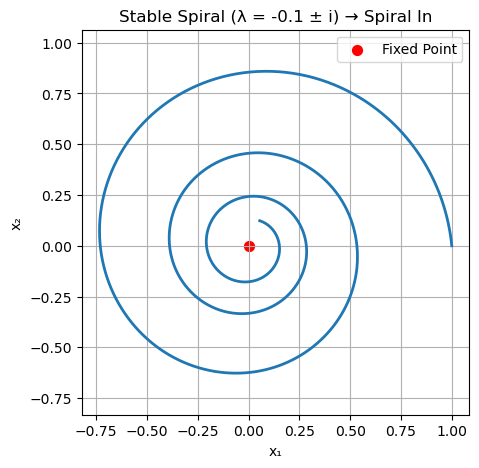

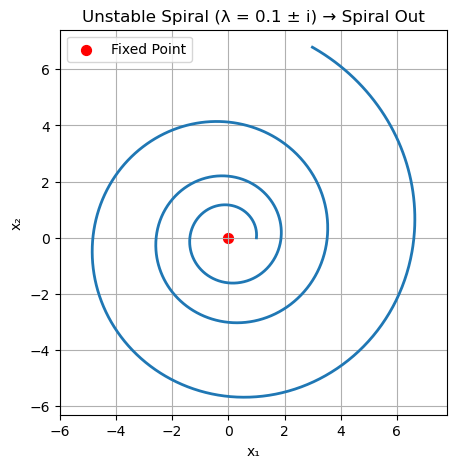

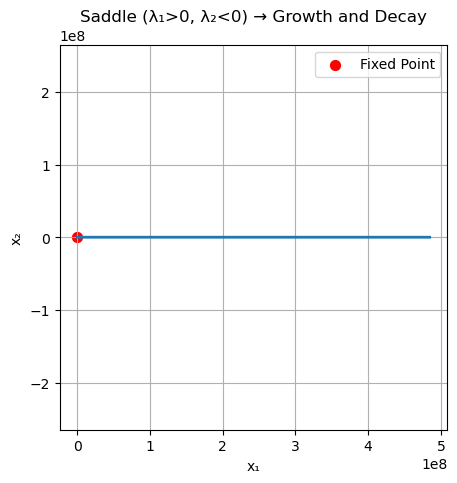

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ---------- 1D System: dx/dt = a*x ----------
def one_d_system(a, x0=1, tmax=5):
    t = np.linspace(0, tmax, 200)
    x = x0 * np.exp(a * t)
    plt.figure(figsize=(8, 4))
    plt.plot(t, x, label=f"a = {a}")
    plt.title("1D System: dx/dt = a·x")
    plt.xlabel("time t")
    plt.ylabel("x(t)")
    plt.legend()
    plt.grid(True)
    plt.show()

# Try different 'a' values
one_d_system(a=-1.0)  # Decay
one_d_system(a=0.5)   # Growth

# ---------- 2D System ----------
def two_d_system(J, x0, tmax=20, title="2D System"):
    def f(t, X):
        return J @ X
    t = np.linspace(0, tmax, 2000)
    sol = solve_ivp(f, [0, tmax], x0, t_eval=t)
    plt.figure(figsize=(5, 5))
    plt.plot(sol.y[0], sol.y[1], lw=2)
    plt.scatter([0], [0], color='red', s=50, label='Fixed Point')
    plt.xlabel("x₁")
    plt.ylabel("x₂")
    plt.axis('equal')
    plt.grid(True)
    plt.legend()
    plt.title(title)
    plt.show()

# Case 1: Pure rotation → eigenvalues ±i
J_rotation = np.array([[0, -1],
                       [1,  0]])
two_d_system(J_rotation, x0=[1, 0], title="Pure Rotation (λ = ±i) → Circular Orbit")

# Case 2: Spiral in → eigenvalues = -0.1 ± i
J_spiral_in = np.array([[-0.1, -1],
                        [ 1,  -0.1]])
two_d_system(J_spiral_in, x0=[1, 0], title="Stable Spiral (λ = -0.1 ± i) → Spiral In")

# Case 3: Spiral out → eigenvalues = +0.1 ± i
J_spiral_out = np.array([[ 0.1, -1],
                         [ 1,   0.1]])
two_d_system(J_spiral_out, x0=[1, 0], title="Unstable Spiral (λ = 0.1 ± i) → Spiral Out")

# Case 4: Pure growth/decay, no rotation → eigenvalues both real
J_real = np.array([[1.0, 0],
                   [0, -1.0]])
two_d_system(J_real, x0=[1, 1], title="Saddle (λ₁>0, λ₂<0) → Growth and Decay")


## Part IV — A two-dimensional system with an analytical solution

### Model 7 — Time evolution and trajectory of a stable node

Consider the constant-coefficient system

$$
\frac{d\mathbf{x}}{dt}=A\mathbf{x},\qquad
A=\begin{pmatrix}1&2\\-3&-4\end{pmatrix},\qquad
\mathbf{x}(0)=\begin{pmatrix}5\\5\end{pmatrix}.
$$

The eigenvalues are $\lambda_1=-1$ and $\lambda_2=-2$, so the origin is a **stable node**: both modes decay exponentially. Combining the eigenvector contributions for this initial state gives

$$
x_1(t)=25e^{-t}-20e^{-2t},\qquad
x_2(t)=-25e^{-t}+30e^{-2t}.
$$

The code plots these analytical components against time and then plots $x_2(t)$ against $x_1(t)$ to display the **phase-plane trajectory**. The time plot shows how each component changes, while the phase portrait shows how the state moves towards the origin without explicitly displaying time.


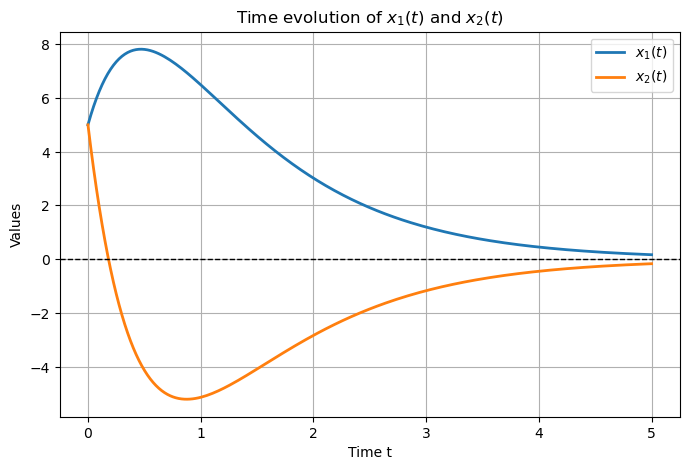

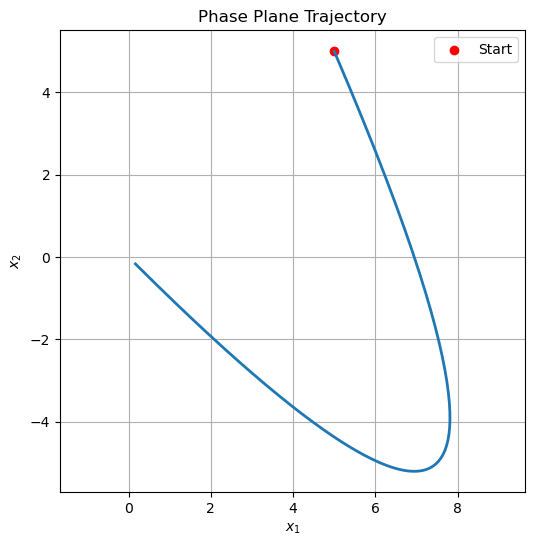

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Time vector
t = np.linspace(0, 5, 200)

# Analytical solution with initial conditions x1(0)=5, x2(0)=5
x1 = 25 * np.exp(-t) - 20 * np.exp(-2*t)
x2 = -25 * np.exp(-t) + 30 * np.exp(-2*t)

# Plotting
plt.figure(figsize=(8,5))
plt.plot(t, x1, label='$x_1(t)$', linewidth=2)
plt.plot(t, x2, label='$x_2(t)$', linewidth=2)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Time evolution of $x_1(t)$ and $x_2(t)$')
plt.xlabel('Time t')
plt.ylabel('Values')
plt.legend()
plt.grid(True)
plt.show()



# Phase plane plot
plt.figure(figsize=(6,6))
plt.plot(x1, x2, linewidth=2)
plt.scatter([x1[0]], [x2[0]], color='red', label='Start')  # initial point
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Phase Plane Trajectory')
plt.grid(True)
plt.legend()
plt.axis('equal')  # equal scaling on both axes
plt.show()


### Model 7A — Eigenvectors as invariant directions

For the same matrix $A$, two eigenvector directions are

$$
\mathbf{v}_1=\begin{pmatrix}1\\-1\end{pmatrix},\qquad
\mathbf{v}_2=\begin{pmatrix}2\\-3\end{pmatrix},
$$

with eigenvalues $-1$ and $-2$, respectively. If a state begins exactly on one eigenvector line, the solution stays on that line and decays at the corresponding exponential rate. A general initial state is a combination of the two modes:

$$
\mathbf{x}(t)=c_1e^{-t}\mathbf{v}_1+c_2e^{-2t}\mathbf{v}_2.
$$

Here the code overlays the two eigenvector arrows on the analytical phase-plane trajectory from $\mathbf{x}(0)=(5,5)$. Notice that the faster-decaying $e^{-2t}$ contribution becomes less important at large $t$, so the trajectory approaches the origin along the direction of the slower $e^{-t}$ mode.


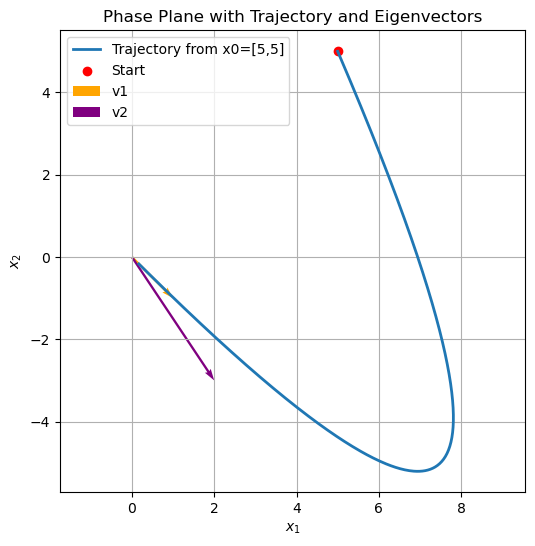

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Time array
t = np.linspace(0, 5, 500)

# Analytic solution from earlier for x0 = [5,5]
x1 = 25 * np.exp(-t) - 20 * np.exp(-2*t)
x2 = -25 * np.exp(-t) + 30 * np.exp(-2*t)

# Eigenvectors
v1 = np.array([1, -1])
v2 = np.array([2, -3])

# Plot phase plane trajectory
plt.figure(figsize=(6,6))
plt.plot(x1, x2, label='Trajectory from x0=[5,5]', linewidth=2)
plt.scatter([x1[0]], [x2[0]], color='red', label='Start')  # initial point

# Plot eigenvectors (scaled for visibility)
plt.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='orange', width=0.005, label='v1')
plt.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='purple', width=0.005, label='v2')

plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Phase Plane with Trajectory and Eigenvectors')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.show()


### Model 7B — The matrix exponential and multiple initial conditions

The solution of a linear autonomous system with constant matrix $A$ can be written as

$$
\mathbf{x}(t)=e^{At}\mathbf{x}_0,
$$

where $e^{At}$ is the **matrix exponential**. Unlike computing one explicit component formula, this approach can be reused for any initial vector $\mathbf{x}_0$. In the present example, the matrix $A$ still has the negative eigenvalues $-1$ and $-2$, so different initial states yield different transient paths but ultimately approach the same stable equilibrium.

The code evaluates `scipy.linalg.expm(A*t)` for four initial conditions and draws their phase-plane trajectories together with the two eigenvector directions. This illustrates how initial conditions change the geometry of the transient even when the underlying system and its stability classification remain fixed.


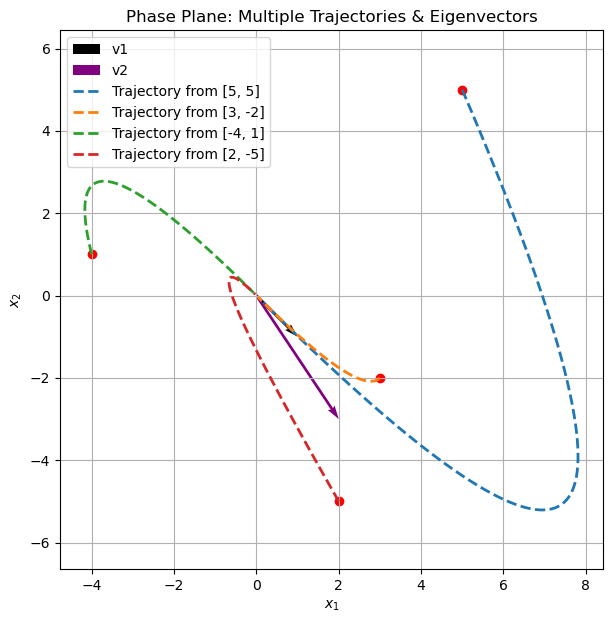

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Define A
A = np.array([[1.0, 2.0],
              [-3.0, -4.0]])

# Time array
t_eval = np.linspace(0, 5, 500)

# Define initial conditions
initial_conditions = [
    [5, 5],
    [3, -2],
    [-4, 1],
    [2, -5]
]

# Eigenvectors
v1 = np.array([1, -1])
v2 = np.array([2, -3])

plt.figure(figsize=(7,7))

# Plot eigenvectors (scaled)
plt.quiver(0, 0, v1[0], v1[1], angles='xy', scale_units='xy', scale=1, color='black', width=0.005, label='v1')
plt.quiver(0, 0, v2[0], v2[1], angles='xy', scale_units='xy', scale=1, color='purple', width=0.005, label='v2')

for x0 in initial_conditions:
    # Analytic solution using matrix exponential
    X = np.column_stack([expm(A * tt).dot(x0) for tt in t_eval])
    x1 = X[0,:]
    x2 = X[1,:]
    plt.plot(x1, x2, linewidth=2, label=f'Trajectory from {x0}',linestyle='--')
    plt.scatter([x0[0]], [x0[1]], color='red')  # mark initial point



plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Phase Plane: Multiple Trajectories & Eigenvectors')
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.show()


### Model 7C — Checking numerical integration against an exact solution

An analytically solvable linear system is a useful **verification problem** for an ODE solver. For the same matrix $A$, there are two independent ways of computing the motion:

$$
\mathbf{x}_{\mathrm{numerical}}(t)
\quad\text{from}\quad\dot{\mathbf{x}}=A\mathbf{x}
$$

and

$$
\mathbf{x}_{\mathrm{exact}}(t)=e^{At}\mathbf{x}_0.
$$

For each initial condition, the script compares the two solutions component-wise and reports their maximum absolute difference over the sampled times:

$$
E_{\max}=\max_{t\in\{t_k\}}\max_{j\in\{1,2\}}
\left|x_{j,\mathrm{numerical}}(t)-x_{j,\mathrm{exact}}(t)\right|.
$$

It also plots the vector field, numerical trajectories, and the eigenvector directions, and prints the eigenvalues and eigenvectors. Agreement with the matrix exponential provides a check on the numerical integration for this particular test problem; it is not a universal guarantee of accuracy for nonlinear or stiff systems.


Run 1 eigenvalues: [-1.+0.j -2.+0.j]
Run 1 eigenvectors (columns):
[[ 0.707107 -0.5547  ]
 [-0.707107  0.83205 ]]

Run 2 eigenvalues: [-1.+0.j -2.+0.j]
Run 2 eigenvectors (columns):
[[ 0.707107 -0.5547  ]
 [-0.707107  0.83205 ]]

Run 3 eigenvalues: [-1.+0.j -2.+0.j]
Run 3 eigenvectors (columns):
[[ 0.707107 -0.5547  ]
 [-0.707107  0.83205 ]]



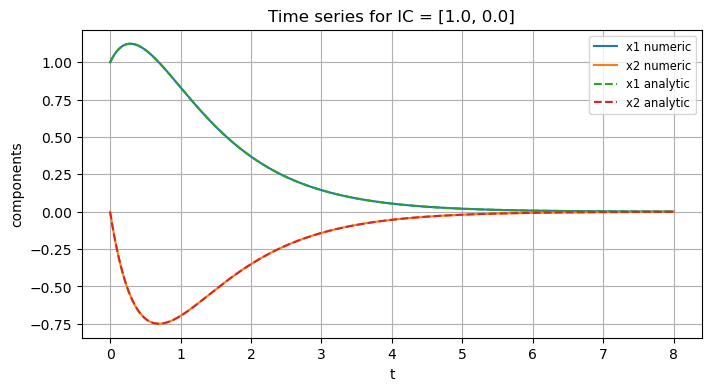

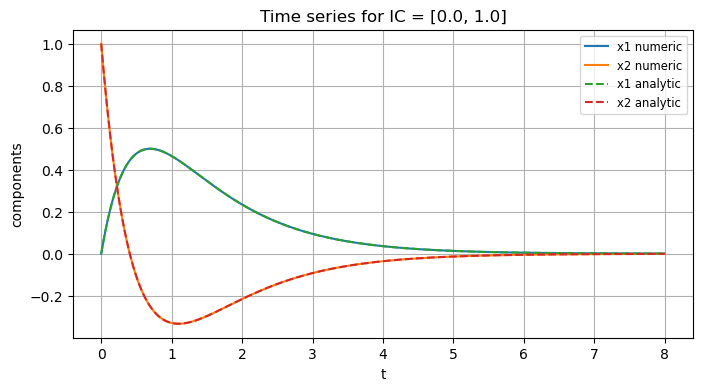

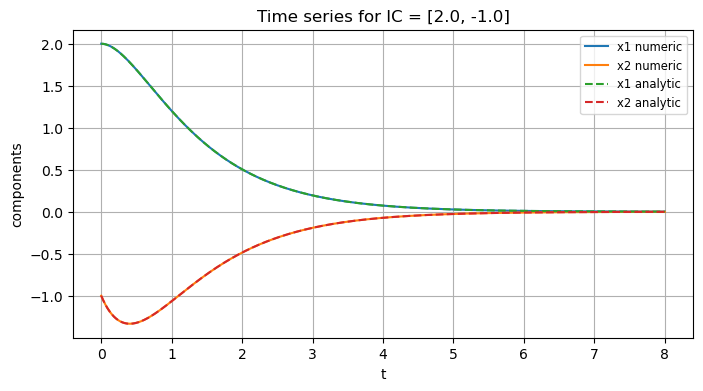

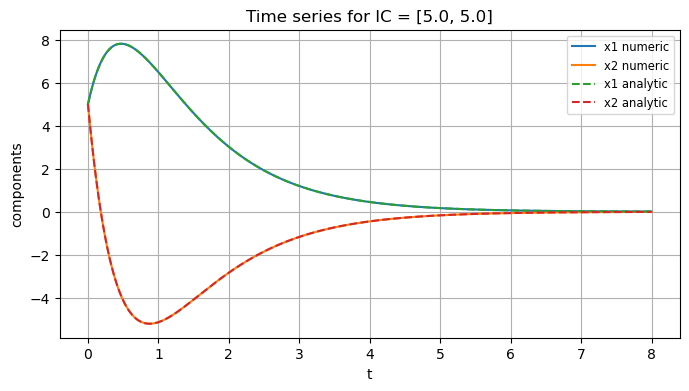

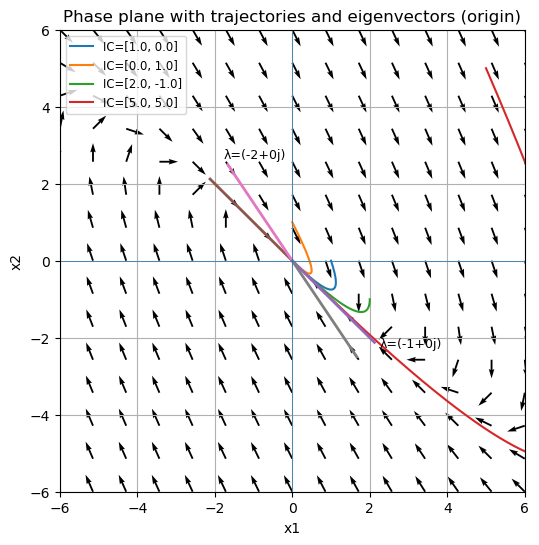

IC [1.0, 0.0] max abs diff numeric vs analytic: 1.6e-10
IC [0.0, 1.0] max abs diff numeric vs analytic: 8.2e-11
IC [2.0, -1.0] max abs diff numeric vs analytic: 3.0e-10
IC [5.0, 5.0] max abs diff numeric vs analytic: 1.2e-09


In [11]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import expm, eig
import matplotlib.pyplot as plt

A = np.array([[1.0, 2.0],
              [-3.0, -4.0]])

# eigen computations (3x)
eig_runs = [eig(A) for _ in range(3)]
for i, (vals, vecs) in enumerate(eig_runs, 1):
    print(f"Run {i} eigenvalues: {np.round(vals,6)}")
    print(f"Run {i} eigenvectors (columns):\n{np.round(vecs,6)}\n")

# ODE setup
def linear_rhs(t, x):
    return A.dot(x)

t_span = (0.0, 8.0)
t_eval = np.linspace(t_span[0], t_span[1], 800)

initial_conditions = [
    np.array([1.0, 0.0]),
    np.array([0.0, 1.0]),
    np.array([2.0, -1.0]),
    np.array([5.0, 5.0])
]

solutions_num = []
solutions_analytic = []
for x0 in initial_conditions:
    sol = solve_ivp(linear_rhs, t_span, x0, t_eval=t_eval, rtol=1e-9, atol=1e-12)
    solutions_num.append(sol)
    X_analytic = np.column_stack([expm(A * tt).dot(x0) for tt in t_eval])
    solutions_analytic.append(X_analytic)

# Time series plots: numeric vs analytic
for sol, x0, X_analytic in zip(solutions_num, initial_conditions, solutions_analytic):
    plt.figure(figsize=(8,4))
    plt.plot(sol.t, sol.y[0], label="x1 numeric")
    plt.plot(sol.t, sol.y[1], label="x2 numeric")
    plt.plot(t_eval, X_analytic[0,:], label="x1 analytic", linestyle='--')
    plt.plot(t_eval, X_analytic[1,:], label="x2 analytic", linestyle='--')
    plt.xlabel("t"); plt.ylabel("components")
    plt.title(f"Time series for IC = {x0.tolist()}")
    plt.legend(fontsize='small'); plt.grid(True); plt.show()

# Phase plane with vector field and eigenvectors
plt.figure(figsize=(6,6))
x_vals = np.linspace(-6, 6, 15)
y_vals = np.linspace(-6, 6, 15)
Xg, Yg = np.meshgrid(x_vals, y_vals)
U = A[0,0]*Xg + A[0,1]*Yg
V = A[1,0]*Xg + A[1,1]*Yg
speed = np.sqrt(U**2 + V**2); speed[speed==0]=1.0
plt.quiver(Xg, Yg, U/speed, V/speed, angles='xy', scale=25)

for sol, x0 in zip(solutions_num, initial_conditions):
    plt.plot(sol.y[0], sol.y[1], label=f"IC={x0.tolist()}")

vals, vecs = eig(A)
for lam, v in zip(vals, vecs.T):
    v = np.real(v)
    plt.plot([0, 3*v[0]], [0, 3*v[1]], linewidth=2)
    plt.plot([0, -3*v[0]], [0, -3*v[1]], linewidth=2)
    plt.text(3.2*v[0], 3.2*v[1], f"λ={np.round(lam,3)}", fontsize=9)

plt.axhline(0, linewidth=0.5); plt.axvline(0, linewidth=0.5)
plt.xlim(-6,6); plt.ylim(-6,6)
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("Phase plane with trajectories and eigenvectors (origin)")
plt.legend(fontsize='small'); plt.grid(True); plt.show()

# numeric vs analytic error check
for x0, sol, X_analytic in zip(initial_conditions, solutions_num, solutions_analytic):
    print(f"IC {x0.tolist()} max abs diff numeric vs analytic: {np.max(np.abs(sol.y - X_analytic)):.1e}")
